# Superstore Sales Performance Analysis

## Project Overview

This project analyzes the Superstore dataset to understand **sales growth, profitability, product sub-category performance, customer segments, regional performance, state-level performance, and discount strategy**.

The goal is to identify where the business performs well, where profitability is weak, and which areas require management attention.

> **Note:** This project is an exploratory data analysis portfolio project. The dataset is used to demonstrate a complete business-oriented data analysis workflow.

## Business Problem

With increasing competition, the Superstore wants to understand which **categories, and sub-categories, regions, states, and customer segments** contribute to profitable growth and which areas require review.

The analysis focuses on identifying:

- Overall sales and profit performance
- Sales growth over time
- Strong and weak product sub-categories
- Customer segment performance
- Regional and state-level profitability
- Loss-making areas
- The relationship between discounts and profit
- Business areas that deserve further investigation

## Business Questions

### Overall Performance
- Is the business growing over time?
- Is the business profitable overall?
- How many transactions are loss-making?

### Product Performance
- Which categories and sub-categories drive sales and profit?
- Which sub-categories generate losses?
- Which sub-categories have both strong sales and strong profit?

### Customer Performance
- Which customer segment contributes the most sales and profit?

### Geographic Performance
- Which regions perform best?
- Which states contribute most to profit?
- Where are losses concentrated?
- Which sub-categories are responsible for weak regional performance?

### Discount Strategy
- Which categories and sub-categories receive higher discounts?
- Are higher discount levels associated with weaker profitability?

### Time Trends
- How do sales and profit change year over year?
- Which months show stronger sales activity?

📖 Want the thinking behind this analysis? Read the story on Medium: [I Stopped Asking “What Can I Find in This Dataset?” and Started Asking “What Should a Business Do?”]([https://medium.com/@parulrajput27/7f80f86e830a?source=friends_link&sk=991c621b9dfa78560d2808d5148d31d7])

## Import Required Libraries 

In [1]:
 #Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import seaborn as sns


sns.set_style("whitegrid")

## Load Dataset

In [2]:
# Load Dataset

data = pd.read_csv(r"/kaggle/input/datasets/vivek468/superstore-dataset-final/Sample - Superstore.csv",encoding="latin1")

In [3]:
data.shape

(9994, 21)

## Data Understanding

In [4]:
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
# dataset inforamation
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

### Data Quality Assesment
Before analysis, we check:

- Missing values
- Duplicate records
- Data types
- Negative values in important measures
- Date validity

In [6]:
#Check missing values 
missing_values = data.isnull().sum().sort_values(ascending=False)

No missing values were found in the dataset.

In [7]:
# check duplicate records
data.duplicated().sum()

np.int64(0)

No duplicate records were identified.


In [8]:
#Statistical Summary
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [9]:
print("Categories:", data["Category"].unique())
print("Regions:", data["Region"].unique())
print("Customer Segments:", data["Segment"].unique())
print("Country:", data["Country"].unique())

Categories: ['Furniture' 'Office Supplies' 'Technology']
Regions: ['South' 'West' 'Central' 'East']
Customer Segments: ['Consumer' 'Corporate' 'Home Office']
Country: ['United States']


## Data Cleaning & Preparation

Before diving into exploratory data analysis, we must ensure data integrity. This step involves:
- Stripping leading/trailing whitespace from string columns to prevent grouping errors.
- Converting date columns (`Order Date`, `Ship Date`) from object types to proper datetime objects.
- Validating data sanity (checking for negative values in Sales, Quantity, Discount, and ensuring Ship Dates do not precede Order Dates).

In [10]:
# create a copy
clean_df = data.copy()

In [11]:
# Select all text columns
text_columns = clean_df.select_dtypes(include='object').columns

# Remove leading and trailing spaces
for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

In [12]:
#convert dates columns
clean_df["Order Date"] = pd.to_datetime(clean_df["Order Date"])
clean_df["Ship Date"] = pd.to_datetime(clean_df["Ship Date"])

In [13]:
# Create time features
clean_df["Year"] = clean_df["Order Date"].dt.year
clean_df["Month"] = clean_df["Order Date"].dt.month
clean_df["Month_Name"] = clean_df["Order Date"].dt.month_name()

In [14]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [15]:
print("Cleaned dataset shape:", clean_df.shape)

Cleaned dataset shape: (9994, 24)


### Data Validation

Now perform the checks on your cleaned dataset.

In [16]:
print("Negative Sales:", (clean_df["Sales"] < 0).sum())
print("Negative Quantity:", (clean_df["Quantity"] < 0).sum())
print("Negative Discount:", (clean_df["Discount"] < 0).sum())
print("Negative Profit:", (clean_df["Profit"] < 0).sum())

Negative Sales: 0
Negative Quantity: 0
Negative Discount: 0
Negative Profit: 1871


No negative values were found in Sales, Quantity, or Discount. However, 1,871 transactions recorded negative profit, indicating that a significant number of orders were sold at a loss. These records were retained because negative profit represents a business performance issue rather than a data quality error.

In [17]:
#Check Shipping Dates (A product cannot be shipped before it is ordered.)
invalid_dates = clean_df[clean_df["Ship Date"] < clean_df["Order Date"]]

print("Invalid Shipping Records:", len(invalid_dates))

Invalid Shipping Records: 0


No records were found where the shipping date occurred before the order date, confirming that the order and shipping timeline is logically consistent.

In [18]:
#Save clean data

clean_df.to_csv(r"superstore\Superstore_Cleaned.csv",
    index=False)

### Dataset Overview

Now we introduce the dataset we will actually analyze.

The cleaned Superstore dataset contains retail transaction records from 2014 to 2017. After validating data quality and converting the required fields, the dataset was prepared for exploratory analysis. It includes customer, product, geographical, and financial information that supports business performance analysis.

In [19]:
# Dataset Overview

dataset_overview = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Features",
        "Analysis Period",
        "Unique Orders",
        "Unique Customers",
        "Unique Products",
        "Categories",
        "Sub-Categories",
        "Regions",
        "States",
        "Cities",
         "Total Sales",
        "Total Profit",
        "Profit Margin",
        "Average Discount",
        "Loss-Making Transactions"
    ],
    "Value": [
            clean_df.shape[0],
            clean_df.shape[1],
        f"{clean_df['Order Date'].min().year} - {clean_df['Order Date'].max().year}",
        clean_df["Order ID"].nunique(),
        clean_df["Customer ID"].nunique(),
        clean_df["Product ID"].nunique(),
        clean_df["Category"].nunique(),
        clean_df["Sub-Category"].nunique(),
        clean_df["Region"].nunique(),
        clean_df["State"].nunique(),
        clean_df["City"].nunique(),
         clean_df["Sales"].sum(),
        clean_df["Profit"].sum(),
        f"{clean_df["Profit"].sum() / clean_df["Sales"].sum() * 100:.1f}%",
        f"{clean_df["Discount"].mean() * 100:.1f}",
        (clean_df["Profit"] < 0).sum()
    ]
})

dataset_overview

,Metric,Value
0,Total Records,9994
1,Total Features,24
2,Analysis Period,2014 - 2017
3,Unique Orders,5009
4,Unique Customers,793
5,Unique Products,1862
6,Categories,3
7,Sub-Categories,17
8,Regions,4
9,States,49


**Observation**
* The final dataset contains 9,994 retail transactions collected over a four-year period (2014–2017).
* It includes 793 unique customers, 1,862 products, and 5,009 orders, providing sufficient data to analyze customer behavior and product performance.
* Sales are distributed across 3 product categories, 17 sub-categories, 4 regions, 49 states, and 531 cities, enabling detailed geographical and product-level analysis.
* After data validation and cleaning, the dataset contains no missing values, duplicate records, or invalid shipping dates, making it suitable for reliable business analysis.

**Observation**

The business remains profitable overall, but 1,871 transactions generated negative profit. The average discount level and profit margin provide important context for investigating whether discounting is contributing to these losses, while sales growth indicates the overall direction of business performance.

## Exploratory Data Analysis & Business Insights

### 1. Product Performance
In this section, we analyze the highest- and lowest-performing products based on sales and profit.

In [20]:
# Product performance

product_performance = (
    clean_df
    .groupby("Product Name")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

In [21]:
#Find Top Products by Sales
top_sales_products = (
    product_performance
    .sort_values(by="Sales", ascending=False)
)

top_sales_products.head()

,Product Name,Sales,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03
786,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14
686,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03


In [22]:
#Find Top Products by Profit
top_profit_products = (
    product_performance
    .sort_values(by="Profit", ascending=False)
)

top_profit_products.head()

,Product Name,Sales,Profit
404,Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7753.0390
805,Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836
400,Canon PC1060 Personal Laser Copier,11619.834,4570.9347
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4094.9766


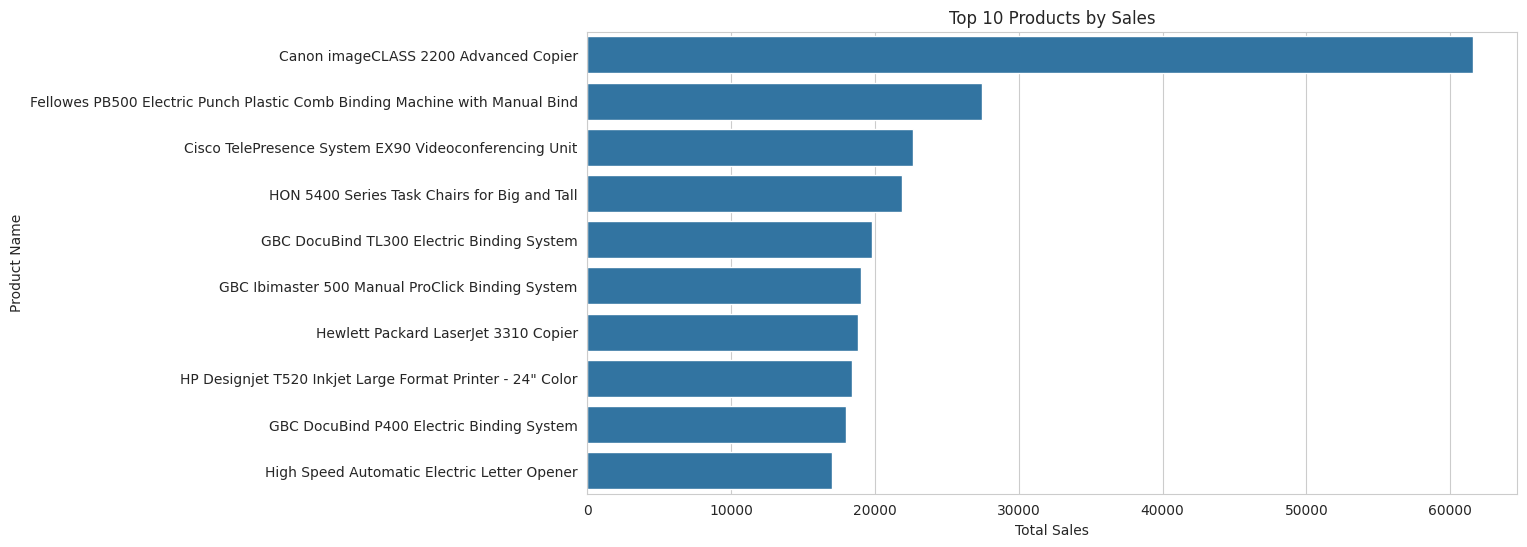

In [23]:
#Top 10 Products by Sales
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_sales_products.head(10),
    x="Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.show()

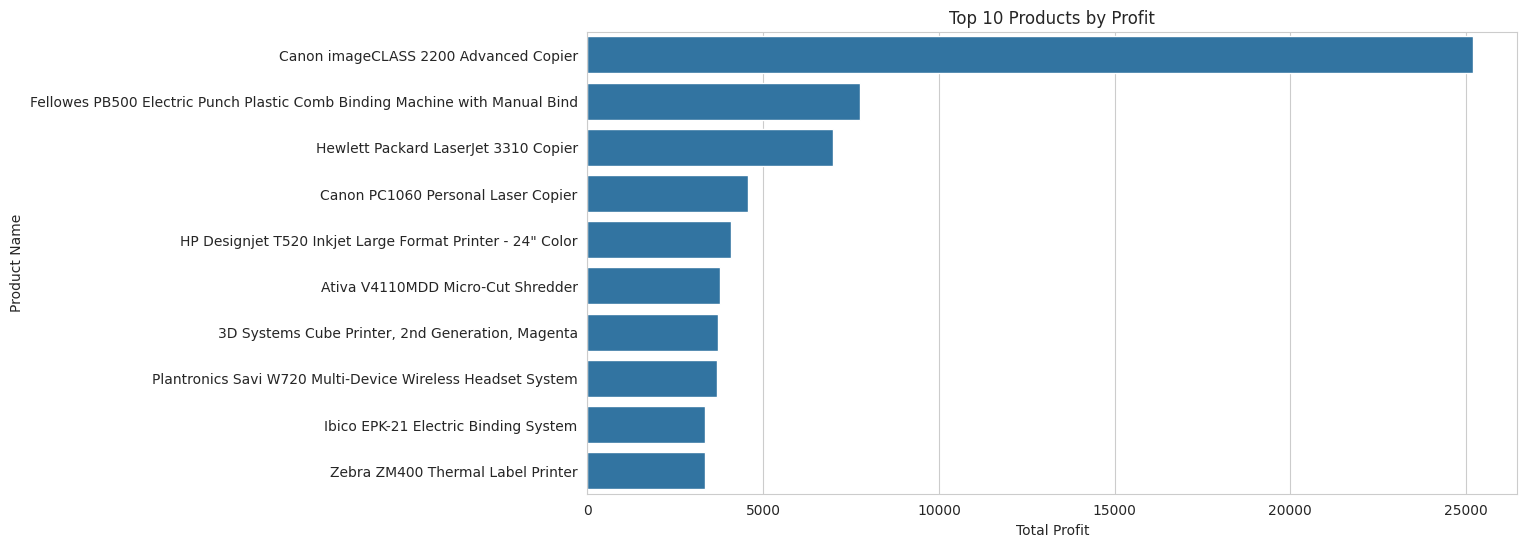

In [24]:
#Top 10 Products by Profit
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_profit_products.head(10),
    x="Profit",
    y="Product Name"
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")

plt.show()

### Category and Sub-Category Performance

Different product categories contribute differently to overall business performance. This analysis evaluates sales and profit across categories and sub-categories to identify the strongest revenue drivers, the most profitable product groups, and areas that require strategic improvement.

In [25]:
#category performance 
category_summary = (
    clean_df
    .groupby(["Category", "Sub-Category"],as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .round(2)
    .reset_index()
)

category_summary

,index,Category,Sub-Category,Total_Sales,Total_Profit
0,0,Furniture,Bookcases,114880.00,-3472.56
1,1,Furniture,Chairs,328449.10,26590.17
2,2,Furniture,Furnishings,91705.16,13059.14
3,3,Furniture,Tables,206965.53,-17725.48
4,4,Office Supplies,Appliances,107532.16,18138.01
5,5,Office Supplies,Art,27118.79,6527.79
6,6,Office Supplies,Binders,203412.73,30221.76
7,7,Office Supplies,Envelopes,16476.40,6964.18
8,8,Office Supplies,Fasteners,3024.28,949.52
9,9,Office Supplies,Labels,12486.31,5546.25


In [26]:
#Total Profit across Product Sub-Category

fig = px.bar(
    category_summary.sort_values("Total_Profit"),
    x="Total_Profit",
    y="Sub-Category",
    color="Category",
    orientation="h",
    text="Total_Profit",
    title="Profit Across Product Sub-Categories"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(template="plotly_white")

fig.show()

**Observation**

* Technology sub-categories, particularly Copiers, Phones, and Accessories, generate the highest profits.
* Tables, Bookcases and supplies are the only sub-categories with overall negative profit.

In [27]:
fig = px.bar(
    category_summary.sort_values("Total_Sales"),
    x="Total_Sales",
    y="Sub-Category",
    color="Category",
    orientation="h",
    text="Total_Sales",
    title="Sales Across Product Sub-Categories"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(template="plotly_white")

fig.show()

**Observation**


* Phones recorded the highest total sales among all sub-categories, followed by Chairs and Storage.
* The Technology category contributes significantly to overall sales through Phones, Machine, Accessories, and Copiers.
* Within the Furniture category, Chairs and Tables generate strong sales, while Bookcases and Furnishings contribute comparatively less.
* Office Supplies show consistent sales across several sub-categories, particularly Storage, Binders, and Appliances.
* Fasteners, Labels, and Envelopes have the lowest sales among all sub-categories.


### Product Sub-Category Performance Matrix

In [28]:
#Product Sub-Category Performance Matrix
segment_product = (
    clean_df
    .groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order ID", "count")
    )
    .reset_index()
)

avg_sales = segment_product["Total_Sales"].mean()
avg_profit = segment_product["Total_Profit"].mean()

segment_product["Quadrant"] = "Maintain"

segment_product.loc[
    (segment_product["Total_Sales"] >= avg_sales) &
    (segment_product["Total_Profit"] >= avg_profit),
    "Quadrant"
] = "Champion"

segment_product.loc[
    (segment_product["Total_Sales"] < avg_sales) &
    (segment_product["Total_Profit"] >= avg_profit),
    "Quadrant"
] = "Growth Opportunity"

segment_product.loc[
    (segment_product["Total_Sales"] >= avg_sales) &
    (segment_product["Total_Profit"] < avg_profit),
    "Quadrant"
] = "Needs Review"


fig = px.scatter(
    segment_product,
    x="Total_Sales",
    y="Total_Profit",
    size="Orders",
    color="Quadrant",
    text="Sub-Category",
    hover_name="Sub-Category",
    size_max=45,
    title="Product Sub-Category Performance Matrix"
)

fig.add_vline(x=avg_sales, line_dash="dash")
fig.add_hline(y=avg_profit, line_dash="dash")

fig.update_traces(
    marker=dict(opacity=0.8),
    textposition="top center"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Sales",
    yaxis_title="Total Profit"
)

fig.show()

**Observation**

* The product performance matrix classifies all product sub-categories into four business priority groups based on their sales and profitability.

* **Phones, Binders, Chairs, Storage, Accessories, and Copiers** are positioned in the Champion quadrant, indicating they generate both above-average sales and above-average profit, making them the strongest contributors to overall business performance.

* **Paper, Appliances** falls into the **Growth Opportunity** quadrant, demonstrating strong profitability despite below-average sales. This suggests it has the potential to generate higher revenue through targeted marketing and increased visibility.

* **Tables and Machines** are located in the **Needs Review** quadrant. Although they generate relatively high sales, their profit is below average, with **Tables** showing a significant negative profit. This indicates that high sales do not necessarily translate into business profitability. 

* Several sub-categories, including **Fasteners, Labels, Envelopes, Supplies, Art, and Bookcases**, fall into the **Maintain** quadrant, contributing below-average sales and profit. While they are not major business drivers, they should continue to be monitored to identify opportunities for performance improvement.

### Customer Segment Performance

Customer segmentation helps businesses understand which groups contribute the most to sales and profitability. By analyzing sales and profit across different customer segments, management can identify high-value customers, optimize marketing strategies, and allocate resources more effectively.

In [29]:
# customer segment performance

segment_performance = (
    clean_df
    .groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .round(2)
    .reset_index()
    .sort_values("Total_Profit", ascending=False)
)

segment_chart = segment_performance.melt(
    id_vars="Segment",
    value_vars=["Total_Sales", "Total_Profit"],
    var_name="Metric",
    value_name="Amount"
)

In [30]:
#Sales and Profit by Customer Segment

fig = px.bar(
    segment_chart,
    x="Segment",
    y="Amount",
    color="Metric",
    barmode="group",
    title="Sales and Profit by Customer Segment"
)

fig.show()

**Observation**

* The Consumer segment generates the highest total sales and the highest total profit among all customer segments.
* The Corporate segment ranks second in both sales and profitability, indicating consistent business performance.
* The Home Office segment contributes the lowest sales and profit, making it the smallest customer segment in terms of revenue generation.
* The ranking of customer segments remains consistent for both sales and profit, suggesting that higher sales are generally associated with higher profitability across segments.


### Geographical Performance Analysis

We first compare overall sales and profit by **region**, then drill down from region → sub-category → state to identify potential root causes.


In [31]:
#group all Country region by category
region_category = (
    clean_df
    .groupby(["Region", "Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .round(2)
)

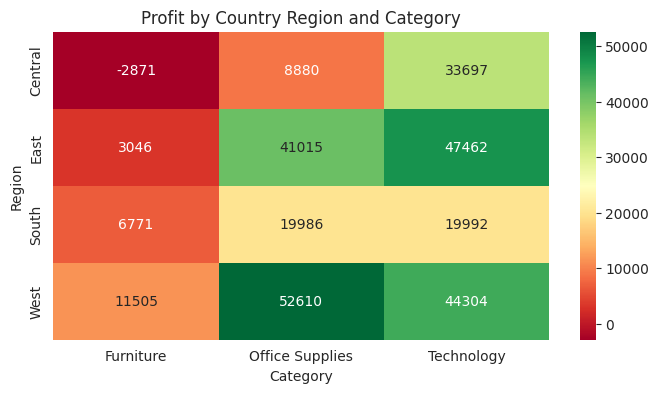

In [32]:
#Profit by Country Region and Category

profit_heatmap = region_category.pivot(
    index="Region",
    columns="Category",
    values="Total_Profit"
)

plt.figure(figsize=(8,4))

sns.heatmap(
    profit_heatmap,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn"
)

plt.title("Profit by Country Region and Category")

plt.show()

**Observation**

* The West region is the strongest overall performer, generating the highest profit in Office Supplies ($52,610) and strong profits in both Technology ($44,304) and Furniture ($11,505).
  
* The East region also performs exceptionally well, particularly in the Technology category, which records the second-highest category profit ($47,462), along with strong profits in Office Supplies ($41,015).

* The Central region is the only region where the Furniture category records a negative profit (-$2,871) despite generating $163,797 in sales. This indicates that sales are not translating into profitability.

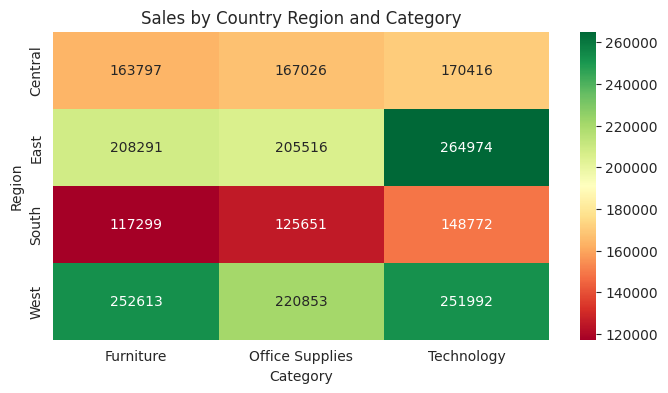

In [33]:
#Sales by Country Region and Category"

sales_heatmap = region_category.pivot(
    index="Region",
    columns="Category",
    values="Total_Sales"
)

plt.figure(figsize=(8,4))

sns.heatmap(
    sales_heatmap,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn"
)

plt.title("Sales by Country Region and Category")

plt.show()

### Observation
* The Central region is the only region where the Furniture category records a negative profit (-$2,871) despite generating $163,797 in sales. This indicates that sales are not translating into profitability.
* The **South region** generates the lowest sales across all three categories and correspondingly lower profits, suggesting relatively weaker market performance.
* Technology consistently generates strong profits across all regions, while Furniture exhibits the greatest variation in profitability, indicating region-specific business challenges.


### Region × Sub-Category Profitability
This drill-down identifies which sub-categories are responsible for regional profit or loss.

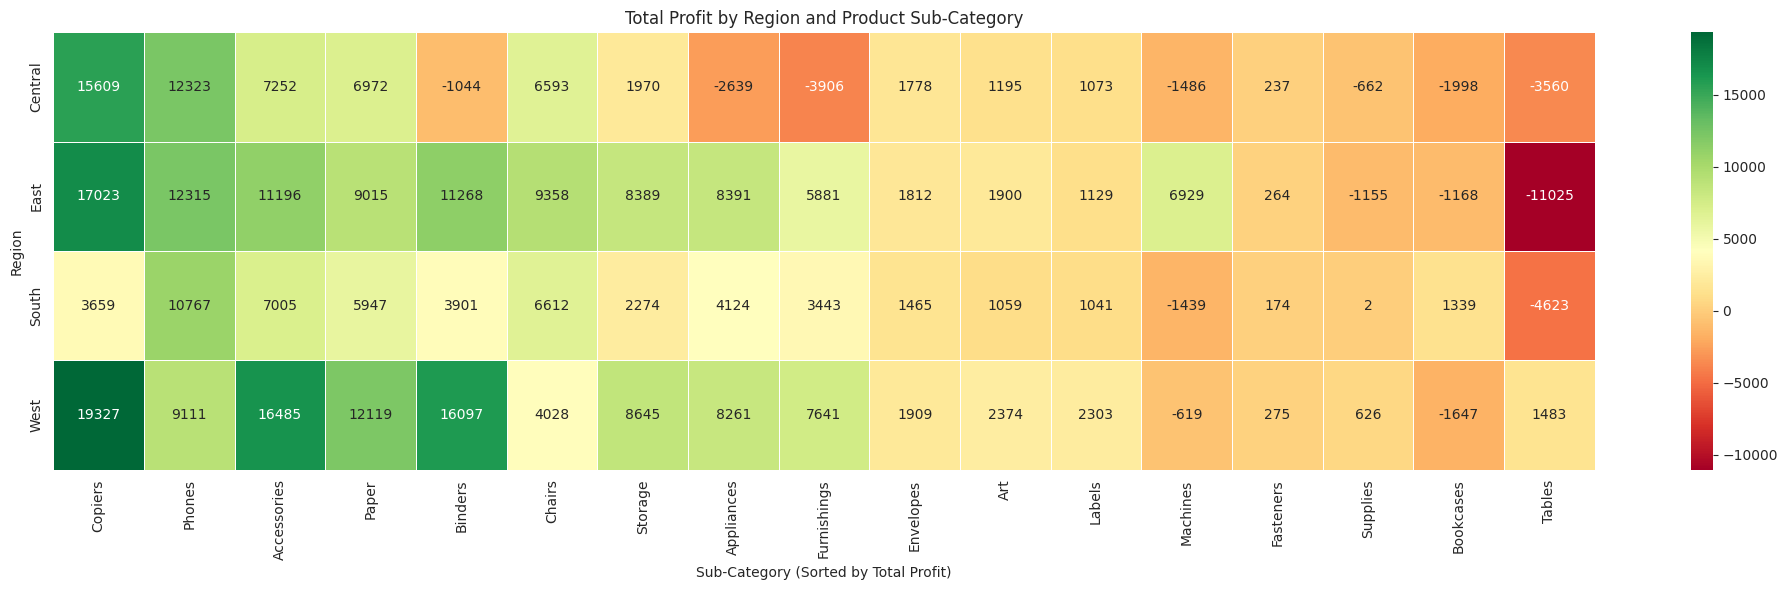

In [34]:
# Region and Sub-Category Summary
region_subcategory = (
    clean_df
    .groupby(["Region", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .round(2)
)

# Get Sub-Category order based on Total Profit (Highest to Lowest)
subcategory_order = (
    clean_df
    .groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .index
)

# Create Profit Heatmap
profit_heatmap = region_subcategory.pivot(
    index="Region",
    columns="Sub-Category",
    values="Total_Profit"
)

# Reorder columns by Total Profit
profit_heatmap = profit_heatmap[subcategory_order]

# Plot
plt.figure(figsize=(20,6))

sns.heatmap(
    profit_heatmap,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    linewidths=0.5
)

plt.title("Total Profit by Region and Product Sub-Category")
plt.xlabel("Sub-Category (Sorted by Total Profit)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

**Observation**

* The West region demonstrates the strongest overall sub-category performance, with **Copiers ($19,327), Accessories ($16,485), Binders ($16,097), and Paper ($12,119)** generating the highest profits.
* **Copiers** are the most profitable sub-category across all regions, consistently generating strong profits, indicating stable demand and healthy profit margins.
* **Phones** also perform consistently well across all regions, contributing significant profits without any regional losses.
* The **Tables** sub-category is the weakest performer, recording negative profits in the Central (-$3,560), East (-$11,025), and South (-$4,623) regions. Only the West region reports a small positive profit ($1,483), indicating a widespread profitability issue.
* **Bookcases,supplies** generate negative profit in every region, suggesting that poor profitability is a company-wide problem rather than a region-specific issue.
* The Central region records losses in several sub-categories, including **Appliances, Binders, Bookcases, Furnishings, Machines, Supplies, and Tables** highlighting it as the most challenging region for product profitability.
* In contrast, the West region has the fewest loss-making sub-categories, demonstrating stronger and more balanced product performance.

### State-Level Performance
The state analysis helps identify where regional performance is concentrated.

In [35]:
#Sales and Profit by Region and State
state_summary = (
    clean_df
    .groupby(["Region", "State"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

state_summary.sort_values("Total_Profit", ascending=False).head(10)

fig = px.treemap(
    state_summary,
    path=["Region", "State"],
    values="Total_Sales",
    color="Total_Profit",
    color_continuous_scale="RdYlGn",
    title="Sales and Profit by Region and State"
)

fig.show()

**Observation**
* **California and New York** remain the strongest contributors, but the treemap also shows that profit within each region is not evenly distributed—a few states contribute most of the region's profit.
* The **Central region** is heavily affected by **Texas**, whose large negative profit has a noticeable impact on the region's overall performance.
* In the **East region, profitable** states such as **New York** offset **losses** from states like **Ohio and Pennsylvania**, resulting in a stronger overall regional performance.
* The **South region** does not have a single major loss-making state; instead, profit is spread across several medium-performing states, indicating opportunities for gradual improvement rather than one critical problem area.

In [36]:
#Highest Profit-Generating States
top_profit_states = (
    state_summary
    .sort_values("Total_Profit", ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

fig = px.bar(
    top_profit_states.sort_values("Total_Profit"),
    x="Total_Profit",
    y="State",
    color="Region",
    orientation="h",
    text="Total_Profit",
    title="Top 10 States by Profit"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(template="plotly_white")

fig.show()

<Figure size 1200x600 with 0 Axes>

In [37]:
# Bottom 10 States by Profit
bottom_profit_states = (
    state_summary
    .sort_values("Total_Profit", ascending=True)
    .head(10)
)

plt.figure(figsize=(12,6))

fig = px.bar(
    bottom_profit_states.sort_values("Total_Profit"),
    x="Total_Profit",
    y="State",
    color="Region",
    orientation="h",
    text="Total_Profit",
    title="Bottom 10 States by Profit"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(template="plotly_white")

fig.show()

<Figure size 1200x600 with 0 Axes>

### Root-Cause Drill Down

After identifying weak regions and states, we investigate the sub-categories contributing to those losses.

This prevents us from stopping at the statement that a region is weak; instead, we ask **where the loss is actually coming from**.

In [38]:
#Find the worst-performing sub-categories in the South
south_subcategory = (
    clean_df[clean_df["Region"] == "South"]
    .groupby("Sub-Category")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum")
        
    )
    .reset_index()
    .sort_values("Total_Profit")
)

south_subcategory

,Sub-Category,Total_Profit,Total_Sales
16,Tables,-4623.0579,43916.192
11,Machines,-1438.8930,53890.960
15,Supplies,1.8773,8318.928
8,Fasteners,173.7181,503.316
10,Labels,1040.7723,2353.180
2,Art,1058.5866,4655.622
4,Bookcases,1339.4918,10899.362
7,Envelopes,1465.4770,3345.556
14,Storage,2274.2965,35768.060
9,Furnishings,3442.6829,17306.684


In [39]:
#texas
texas_subcategory = (
    clean_df[clean_df["State"] == "Texas"]
    .groupby("Sub-Category")
    .agg(
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum")
        
    )
    .reset_index()
    .sort_values("Total_Profit")
)

texas_subcategory

,Sub-Category,Total_Profit,Total_Sales
3,Binders,-14705.0738,9042.6760
1,Appliances,-6147.2225,2407.8140
9,Furnishings,-3312.6786,3766.7240
11,Machines,-2666.8434,19546.2240
5,Chairs,-2515.6490,26572.4480
4,Bookcases,-2391.1377,14493.4588
16,Tables,-2216.6766,15760.6610
15,Supplies,-837.2795,4516.7600
14,Storage,-763.7054,15723.5840
8,Fasteners,80.7357,332.4640


 ### Discount Strategy
 Discounting is analyzed as a possible profitability factor.

A high discount does not automatically cause a loss, but the relationship between discount level and profit can identify areas requiring deeper investigation.

In [40]:
#discount category
discount_category = (
    clean_df
    .groupby("Category")
    .agg(
        Average_Discount=("Discount", "mean"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

discount_category

,Category,Average_Discount,Total_Profit
0,Furniture,0.173923,18451.2728
1,Office Supplies,0.157285,122490.8008
2,Technology,0.132323,145454.9481


In [41]:
#Average Discount vs Total Profit by Category

fig = px.scatter(
    discount_category,
    x="Average_Discount",
    y="Total_Profit",
    size="Total_Profit",
    color="Category",
    text="Category",
    title="Average Discount vs Total Profit by Category"
)

fig.update_traces(textposition="top center")
fig.update_layout(template="plotly_white")

fig.show()

In [42]:

discount_level = (
    clean_df
    .groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Transactions=("Order ID", "count")
    )
    .reset_index()
)

discount_level

fig = px.line(
    discount_level,
    x="Discount",
    y="Total_Profit",
    markers=True,
    title="Profit by Discount Level"
)

fig.add_hline(y=0, line_dash="dash")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Discount",
    yaxis_title="Total Profit"
)

fig.show()

Observation

Categories receive different average discount levels.
No clear relationship exists between higher discounts and higher profit.
Tables remain loss-making despite receiving relatively high discounts.

## 7. Time Trend Analysis

### Business Objective

This analysis evaluates yearly sales and profit trends to understand the company's growth over time. By comparing annual performance, management can determine whether the business is expanding, identify changes in profitability, and recognize years that require further investigation.

In [43]:
# Create yearly summary
yearly_summary = (
    clean_df
    .groupby("Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .sort_values("Year")
)


# Calculate Year-over-Year Sales Growth % & Profit growth %
yearly_summary["Sales_Growth_%"] = (
    yearly_summary["Total_Sales"].pct_change() * 100
).round(1)

yearly_summary["Profit_Growth_%"] = (
    yearly_summary["Total_Profit"].pct_change() * 100
).round(1)


In [44]:

# Year-over-Year Sales Trend
fig = px.bar(
    yearly_summary,
    x="Year",
    y="Total_Sales",
    text="Total_Sales",
    title="Year-over-Year Sales Trend"
)

# Sales Labels
fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

# Add YoY Growth % above bars
for _, row in yearly_summary.iterrows():

    if pd.notna(row["Sales_Growth_%"]):

        fig.add_annotation(
            x=row["Year"],
            y=row["Total_Sales"] + 100000,  # Adjust if needed
            text=f"<b>{row['Sales_Growth_%']:+.1f}%</b>",
            showarrow=False,
            font=dict(
                size=12,
                color="green" if row["Sales_Growth_%"] > 0 else "red"
            )
        )

# Layout
fig.update_layout(
    template="plotly_white",
    xaxis_title="Year",
    yaxis_title="Total Sales (USD)",
    coloraxis_showscale=False
)

fig.update_xaxes(
    tickmode="array",
    tickvals=yearly_summary["Year"]
)

fig.show()

**Observation**
* Sales remained relatively stable between 2014 ($484K) and 2015 ($471K), showing a slight decline of around 2.8%.
* A strong recovery began in 2016, with sales increasing to $609K, indicating improved business performance.
2017 recorded the highest annual sales ($733K), representing the strongest revenue performance during the four-year period.
* Overall, the company demonstrated a positive sales growth trend after 2015, suggesting successful expansion in later years

In [45]:
# Year-over-Year Profit Trend
fig = px.bar(
    yearly_summary,
    x="Year",
    y="Total_Profit",
    text="Total_Profit",
    title="Year-over-Year Profit Trend"
)

# Sales Labels
fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

# Add YoY Growth % above bars
for _, row in yearly_summary.iterrows():

    if pd.notna(row["Profit_Growth_%"]):

        fig.add_annotation(
            x=row["Year"],
            y=row["Total_Profit"] + 10000,  # Adjust if needed
            text=f"<b>{row['Profit_Growth_%']:+.1f}%</b>",
            showarrow=False,
            font=dict(
                size=12,
                color="green" if row["Profit_Growth_%"] > 0 else "red"
            )
        )

# Layout
fig.update_layout(
    template="plotly_white",
    xaxis_title="Year",
    yaxis_title="Total Profit",
    coloraxis_showscale=False
)

fig.update_xaxes(
    tickmode="array",
    tickvals=yearly_summary["Year"]
)

fig.show()

In [46]:
monthly_summary = (
    clean_df
    .groupby(["Year", "Month", "Month_Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .sort_values(["Year", "Month"])
)

monthly_summary.head()

fig = px.line(
    monthly_summary,
    x="Month_Name",
    y="Total_Sales",
    color="Year",
    markers=True,
    category_orders={
        "Month_Name": [
            "January", "February", "March", "April",
            "May", "June", "July", "August",
            "September", "October", "November", "December"
        ]
    },
    title="Monthly Sales Trend by Year"
)

fig.update_layout(template="plotly_white")
fig.show()

**Observation**

* November is consistently one of the strongest sales months, especially in 2017, indicating a strong year-end demand pattern.
* September and December also show strong sales, particularly in 2016–2017.February is consistently a low-sales month across the years.
* 2017 performs above the earlier years for most months, showing that the overall growth seen in the yearly analysis is also visible at the monthly level.
* Sales are not steadily increasing month by month; instead, the business shows clear seasonal peaks and dips.
* The sharp rise around September–November suggests that inventory and promotional planning should be stronger before the year-end peak


### Conclusion

The analysis shows that Superstore has overall positive and growing performance, but sales growth does not always translate into higher profitability. Technology and the West region are key strengths, while Tables, Bookcases, Central region, and Texas require attention. High discounts also appear to be associated with weaker profitability in several areas.

Overall, the business should focus not only on increasing sales, but on improving the profitability of products, regions, and discount strategies that are currently underperforming.

**📖 Want the thinking behind this analysis? Read the story on Medium: I Stopped Asking “What Can I Find in This Dataset?” and Started Asking “What Should a Business Do?”**

# Happy Analysing!! 